Week 2: Machine Learning Model Development

In [104]:
import pandas as pd

df = pd.read_csv("../data/electricity_cleaned.csv")

In [105]:
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime,Month
0,0.256,0.106,242.00,1.2,0.0,0.0,1.0,2010-07-07 18:10:00,7
1,0.466,0.352,237.22,2.4,0.0,2.0,0.0,2007-05-14 06:50:00,5
2,0.758,0.194,238.66,3.2,0.0,1.0,0.0,2007-09-26 18:10:00,9
3,1.290,0.046,240.64,5.4,1.0,0.0,18.0,2007-06-19 07:30:00,6
4,0.428,0.202,242.23,1.8,0.0,2.0,1.0,2010-05-10 04:43:00,5


In [106]:
df.shape

(98759, 9)

In [107]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98759 entries, 0 to 98758
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Global_active_power    98759 non-null  float64
 1   Global_reactive_power  98759 non-null  float64
 2   Voltage                98759 non-null  float64
 3   Global_intensity       98759 non-null  float64
 4   Sub_metering_1         98759 non-null  float64
 5   Sub_metering_2         98759 non-null  float64
 6   Sub_metering_3         98759 non-null  float64
 7   Datetime               98759 non-null  object 
 8   Month                  98759 non-null  int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 6.8+ MB


In [108]:
X = df.drop("Global_active_power", axis=1)
y = df["Global_active_power"]

In [109]:
X.head()

,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime,Month
0,0.106,242.00,1.2,0.0,0.0,1.0,2010-07-07 18:10:00,7
1,0.352,237.22,2.4,0.0,2.0,0.0,2007-05-14 06:50:00,5
2,0.194,238.66,3.2,0.0,1.0,0.0,2007-09-26 18:10:00,9
3,0.046,240.64,5.4,1.0,0.0,18.0,2007-06-19 07:30:00,6
4,0.202,242.23,1.8,0.0,2.0,1.0,2010-05-10 04:43:00,5


In [110]:
y.head()

0    0.256
1    0.466
2    0.758
3    1.290
4    0.428
Name: Global_active_power, dtype: float64

In [111]:
print(X.shape)
print(y.shape)

(98759, 8)
(98759,)


In [112]:
X = X.drop(columns=["Datetime"])

In [113]:
X.dtypes

Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
Month                      int64
dtype: object

In [114]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [115]:
print("Training Features :",X_train.shape)
print("Testing Features :",X_test.shape)
print("Training Labels :",y_train.shape)
print("Testing Labels :",y_test.shape)

Training Features : (79007, 7)
Testing Features : (19752, 7)
Training Labels : (79007,)
Testing Labels : (19752,)


In [116]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [117]:
print(X_train.shape)
print(X_test.shape)

(79007, 7)
(19752, 7)


In [118]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

In [119]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

In [120]:
linear_model = LinearRegression()

decision_tree = DecisionTreeRegressor(
    random_state=42
)

random_forest = RandomForestRegressor(
    random_state=42,
    n_estimators=100
)

gradient_boost = GradientBoostingRegressor(
    random_state=42
)

In [121]:
linear_model.fit(
    X_train,
    y_train
)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [122]:
linear_pred = linear_model.predict(X_test)

In [123]:
print("Linear Regression Results")
print("MAE :", mean_absolute_error(y_test, linear_pred))
print("MSE :", mean_squared_error(y_test, linear_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, linear_pred)))
print("R2 Score :", r2_score(y_test, linear_pred))

Linear Regression Results
MAE : 0.025868272910298667
MSE : 0.0016103752030083049
RMSE : 0.0401294804726937
R2 Score : 0.998579873451239


In [124]:
decision_tree.fit(
    X_train,
    y_train
)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [125]:
decision_pred = decision_tree.predict(X_test)

In [126]:
print("Decision Tree Results")
print("MAE :", mean_absolute_error(y_test, decision_pred))
print("MSE :", mean_squared_error(y_test, decision_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, decision_pred)))
print("R2 Score :", r2_score(y_test, decision_pred))

Decision Tree Results
MAE : 0.024839459295261237
MSE : 0.0021089782919310562
RMSE : 0.045923613663681306
R2 Score : 0.9981401749992567


In [130]:
print(random_forest)
random_forest.fit(X_train,y_train)

RandomForestRegressor(random_state=42)


,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [131]:
print("Random Forest Results")
print("MAE :", mean_absolute_error(y_test, forest_pred))
print("MSE :", mean_squared_error(y_test, forest_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, forest_pred)))
print("R2 Score :", r2_score(y_test, forest_pred))

Random Forest Results
MAE : 0.019417500247477095
MSE : 0.0012260231333255012
RMSE : 0.03501461313973783
R2 Score : 0.9989188184233225


In [132]:
gradient_boost.fit(
    X_train,
    y_train
)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [133]:
gradient_pred = gradient_boost.predict(X_test)

In [ ]:
print("Gradient Boosting Results")
print("MAE :", mean_absolute_error(y_test, gradient_pred))
print("MSE :", mean_squared_error(y_test, gradient_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, gradient_pred)))
print("R2 Score :", r2_score(y_test, gradient_pred))

Gradient Boosting Results
MAE : 0.021219802037725995
MSE : 0.0011624968177677717
RMSE : 0.03409540757591514
R2 Score : 0.9989748397822581


In [ ]:
results = {
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],

    "R2 Score": [
        r2_score(y_test, linear_pred),
        r2_score(y_test, decision_pred),
        r2_score(y_test, forest_pred),
        r2_score(y_test, gradient_pred)
    ]
}

comparison = pd.DataFrame(results)

comparison.sort_values(
    by="R2 Score",
    ascending=False
)

,Model,R2 Score
3,Gradient Boosting,0.998975
2,Random Forest,0.998919
0,Linear Regression,0.998580
1,Decision Tree,0.998140


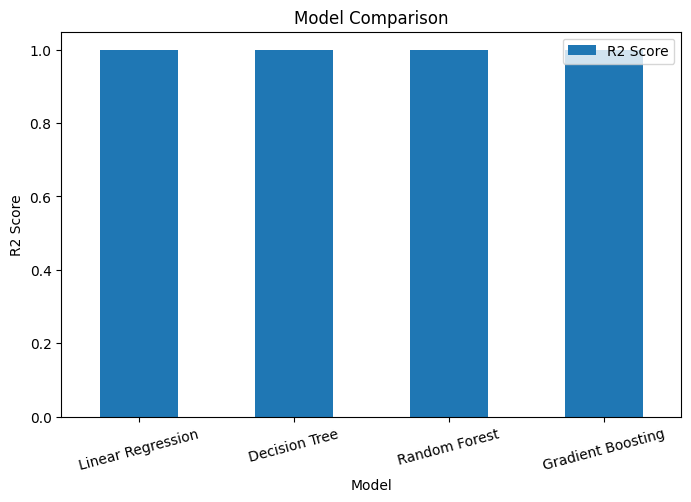

In [ ]:
import matplotlib.pyplot as plt

comparison.plot(
    x="Model",
    y="R2 Score",
    kind="bar",
    figsize=(8,5)
)

plt.title("Model Comparison")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)

plt.show()

In [134]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd

In [135]:
def evaluate_model(model_name, y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    mse = mean_squared_error(y_true, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_true, y_pred)

    print("="*50)
    print(model_name)
    print("="*50)

    print("MAE :", mae)
    print("MSE :", mse)
    print("RMSE :", rmse)
    print("R2 Score :", r2)

    return [model_name, mae, mse, rmse, r2]

In [136]:
linear_result = evaluate_model(
    "Linear Regression",
    y_test,
    linear_pred
)

Linear Regression
MAE : 0.025868272910298667
MSE : 0.0016103752030083049
RMSE : 0.0401294804726937
R2 Score : 0.998579873451239


In [137]:
decision_result = evaluate_model(
    "Decision Tree",
    y_test,
    decision_pred
)

Decision Tree
MAE : 0.024839459295261237
MSE : 0.0021089782919310562
RMSE : 0.045923613663681306
R2 Score : 0.9981401749992567


In [138]:
forest_result = evaluate_model(
    "Random Forest",
    y_test,
    forest_pred
)

Random Forest
MAE : 0.019417500247477095
MSE : 0.0012260231333255012
RMSE : 0.03501461313973783
R2 Score : 0.9989188184233225


In [139]:
gradient_result = evaluate_model(
    "Gradient Boosting",
    y_test,
    gradient_pred
)

Gradient Boosting
MAE : 0.021219802037725995
MSE : 0.0011624968177677717
RMSE : 0.03409540757591514
R2 Score : 0.9989748397822581


In [140]:
comparison = pd.DataFrame(
    [
        linear_result,
        decision_result,
        forest_result,
        gradient_result
    ],

    columns=[
        "Model",
        "MAE",
        "MSE",
        "RMSE",
        "R2 Score"
    ]
)

comparison

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.025868,0.001610,0.040129,0.998580
1,Decision Tree,0.024839,0.002109,0.045924,0.998140
2,Random Forest,0.019418,0.001226,0.035015,0.998919
3,Gradient Boosting,0.021220,0.001162,0.034095,0.998975


In [141]:
comparison.sort_values(
    by="R2 Score",
    ascending=False
)

,Model,MAE,MSE,RMSE,R2 Score
3,Gradient Boosting,0.021220,0.001162,0.034095,0.998975
2,Random Forest,0.019418,0.001226,0.035015,0.998919
0,Linear Regression,0.025868,0.001610,0.040129,0.998580
1,Decision Tree,0.024839,0.002109,0.045924,0.998140


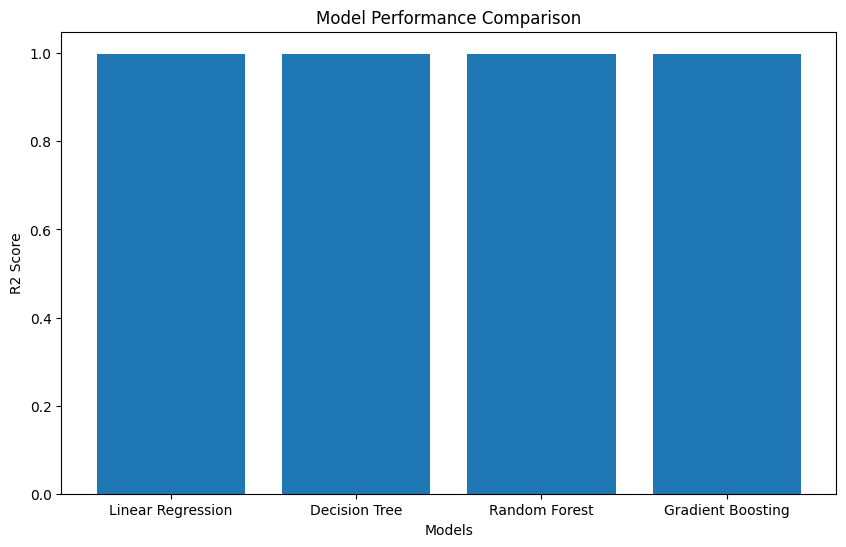

In [142]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.bar(
    comparison["Model"],
    comparison["R2 Score"]
)

plt.xlabel("Models")

plt.ylabel("R2 Score")

plt.title("Model Performance Comparison")

plt.show()

In [143]:
best_model = comparison.loc[
    comparison["R2 Score"].idxmax()
]

best_model

Model       Gradient Boosting
MAE                   0.02122
MSE                  0.001162
RMSE                 0.034095
R2 Score             0.998975
Name: 3, dtype: object

In [147]:
print("Best Model")
print(best_model["Model"])
print("R2 Score :", best_model["R2 Score"])

Best Model
Gradient Boosting
R2 Score : 0.9989748397822581


In [145]:
comparison.to_csv(
    "../data/model_comparison.csv",
    index=False
)

In [146]:
comparison

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.025868,0.001610,0.040129,0.998580
1,Decision Tree,0.024839,0.002109,0.045924,0.998140
2,Random Forest,0.019418,0.001226,0.035015,0.998919
3,Gradient Boosting,0.021220,0.001162,0.034095,0.998975
